In [7]:
%run "/Users/Farid Srouji/Documents/Research/master/financialmodelingprep/code/Initialization/Initialization.ipynb"

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
#
# Load AutoReg class from statsmodels.tsa.ar_model module
#
from statsmodels.tsa.ar_model import AutoReg

P-value:  8.92844093775707e-09


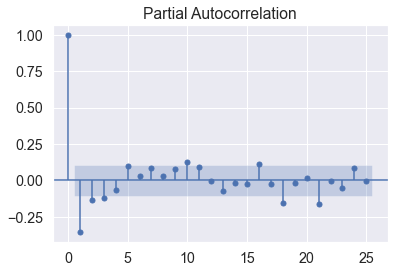

In [8]:
#
# Check for stationarity of the time-series data
# We will look for p-value. In case, p-value is less than 0.05, the time series
# data can said to have stationarity
#
from statsmodels.tsa.stattools import adfuller
#
# Run the test
#
df_stationarityTest = adfuller(df['sentiment_ln_return'], autolag='AIC')
#
# Check the value of p-value
#
print("P-value: ", df_stationarityTest[1])
#
# Next step is to find the order of AR model to be trained
# for this, we will plot partial autocorrelation plot to assess
# the direct effect of past data on future data
#
from statsmodels.graphics.tsaplots import plot_pacf
pacf = plot_pacf(df['sentiment_ln_return'], lags=25)

In [11]:
#
# Create training and test data
#
train_data = df['sentiment_ln_return'][:len(df)-100]
test_data = df['sentiment_ln_return'][len(df)-100:]
#
# Instantiate and fit the AR model with training data
#
ar_model = AutoReg(train_data, lags=8).fit()
#
# Print Summary
#
print(ar_model.summary())

                             AutoReg Model Results                             
Dep. Variable:     sentiment_ln_return   No. Observations:                  243
Model:                      AutoReg(8)   Log Likelihood                 184.262
Method:                Conditional MLE   S.D. of innovations              0.110
Date:                 Mon, 11 Oct 2021   AIC                             -4.321
Time:                         18:25:29   BIC                             -4.174
Sample:                              8   HQIC                            -4.262
                                   243                                         
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
intercept                 -0.0087      0.007     -1.163      0.245      -0.023       0.006
sentiment_ln_return.L1    -0.4106      0.065     -6.321      0.000      -0.538      -0.

In [20]:
pred

243    0.016027
244   -0.019139
245    0.006146
246   -0.017789
247   -0.009369
         ...   
338   -0.006757
339   -0.006757
340   -0.006757
341   -0.006757
342   -0.006757
Length: 100, dtype: float64

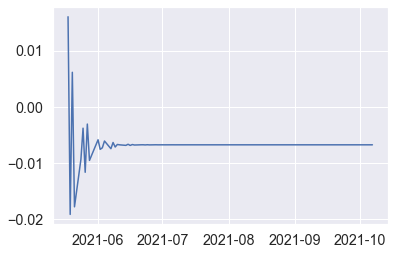

In [28]:
#
# Make the predictions
#
pred = ar_model.predict(start=len(train_data), end=(len(df)-1), dynamic=False)
#
# Plot the prediction vs test data
#
from matplotlib import pyplot
test_data.index = pd.to_datetime(test_data.index)
pred.index = test_data.index
pyplot.plot(pred)

# pyplot.plot(test_data, color='red')